# AI Dermatology Assistant - Multi-Class Skin Disease Prediction

## Objective
Build a multi-class machine learning model that predicts the most probable skin disease based on a patient's symptoms and health attributes.

## Algorithms Used
- Logistic Regression
- Decision Tree Classifier
- Random Forest Classifier
- XGBoost Classifier

In [21]:
# ==========================================
# Import Required Libraries
# ==========================================

import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Encoding and Scaling
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Train Test Split
from sklearn.model_selection import train_test_split

# ML Algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Save Model
import joblib

All required libraries for preprocessing, model building, evaluation and model saving are imported.

In [22]:
# ==========================================
# Load Clean Dataset
# ==========================================

df = pd.read_csv("../data/dermatology_cleaned_dataset.csv")

In [23]:
df.head()

,patient_id,gender,body_area,itching_level,rash_type,skin_peeling,burning_sensation,swelling,fever,skin_color_change,...,stress_level,skin_type,disease,age,bmi,body_temperature,symptom_duration_days,severity_score,sleep_hours,water_intake_liters
0,6d05315f-022d-485b-a809-ab4e7ec3f2a3,Female,Face,Mild,Red Rash,Yes,No,Yes,No,No,...,High,Dry,Rosacea,40.0,18.0,98.7,30.0,5.0,7.3,3.1
1,35ced9a2-0e8d-414a-b3c2-1e58f8199e69,Male,Arms,Mild,Red Rash,Yes,No,Yes,No,Yes,...,High,Oily,Urticaria,47.0,24.7,97.6,60.0,7.0,5.5,1.6
2,c261d043-e7c5-4236-be9e-0213c6cbb035,Male,Feet,Severe,Circular Rash,No,No,Yes,No,Yes,...,High,Normal,Fungal Infection,38.0,26.2,98.5,5.0,5.0,7.1,2.0
3,70fad4ca-165b-4dc5-a9d9-e2c097edd257,Male,Feet,Mild,White Patch,Yes,Yes,Yes,No,No,...,High,Oily,Acne,26.0,21.9,99.4,2.0,8.0,5.9,1.3
4,4f298dad-4c13-413f-8c43-06e7291569c0,Other,Legs,Mild,Blisters,No,No,Yes,No,Yes,...,High,Sensitive,Ringworm,35.0,24.6,98.8,90.0,5.0,5.5,2.6


The cleaned dataset is loaded for model training. All preprocessing performed in Notebook 2 is reflected in this dataset

In [24]:
# Dataset Information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6735 entries, 0 to 6734
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   patient_id             6735 non-null   str    
 1   gender                 6735 non-null   str    
 2   body_area              6735 non-null   str    
 3   itching_level          6735 non-null   str    
 4   rash_type              6735 non-null   str    
 5   skin_peeling           6735 non-null   str    
 6   burning_sensation      6735 non-null   str    
 7   swelling               6735 non-null   str    
 8   fever                  6735 non-null   str    
 9   skin_color_change      6735 non-null   str    
 10  pain                   6735 non-null   str    
 11  dry_skin               6735 non-null   str    
 12  pus_or_discharge       6735 non-null   str    
 13  family_history         6735 non-null   str    
 14  allergy_history        6735 non-null   str    
 15  recent_new_prod

In [25]:
# Check Remaining Missing Values

df.isnull().sum()

patient_id               0
gender                   0
body_area                0
itching_level            0
rash_type                0
skin_peeling             0
burning_sensation        0
swelling                 0
fever                    0
skin_color_change        0
pain                     0
dry_skin                 0
pus_or_discharge         0
family_history           0
allergy_history          0
recent_new_product       0
humidity_exposure        0
stress_level             0
skin_type                0
disease                  0
age                      0
bmi                      0
body_temperature         0
symptom_duration_days    0
severity_score           0
sleep_hours              0
water_intake_liters      0
dtype: int64

The dataset contains no missing values and is ready for feature encoding and model training.

In [26]:
# ==========================================
# Drop Patient ID
# ==========================================

df = df.drop(columns=["patient_id"])

In [27]:
df.head()

,gender,body_area,itching_level,rash_type,skin_peeling,burning_sensation,swelling,fever,skin_color_change,pain,...,stress_level,skin_type,disease,age,bmi,body_temperature,symptom_duration_days,severity_score,sleep_hours,water_intake_liters
0,Female,Face,Mild,Red Rash,Yes,No,Yes,No,No,Yes,...,High,Dry,Rosacea,40.0,18.0,98.7,30.0,5.0,7.3,3.1
1,Male,Arms,Mild,Red Rash,Yes,No,Yes,No,Yes,Yes,...,High,Oily,Urticaria,47.0,24.7,97.6,60.0,7.0,5.5,1.6
2,Male,Feet,Severe,Circular Rash,No,No,Yes,No,Yes,Yes,...,High,Normal,Fungal Infection,38.0,26.2,98.5,5.0,5.0,7.1,2.0
3,Male,Feet,Mild,White Patch,Yes,Yes,Yes,No,No,No,...,High,Oily,Acne,26.0,21.9,99.4,2.0,8.0,5.9,1.3
4,Other,Legs,Mild,Blisters,No,No,Yes,No,Yes,No,...,High,Sensitive,Ringworm,35.0,24.6,98.8,90.0,5.0,5.5,2.6


patient_id is only an identifier and has no predictive value.

In [28]:
# Check number of unique values in each categorical column
cat_cols = df.select_dtypes(include=["object", "string"]).columns

unique_counts = pd.DataFrame({
    "Column": cat_cols,
    "Unique Values": [df[col].nunique() for col in cat_cols]
})

unique_counts.sort_values("Unique Values")

,Column,Unique Values
7,fever,2
6,swelling,2
5,burning_sensation,2
4,skin_peeling,2
11,pus_or_discharge,2
10,dry_skin,2
9,pain,2
8,skin_color_change,2
12,family_history,2
13,allergy_history,2


In [29]:
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    print("="*30, f"Value Counts of {col}", "="*30)
    print(df[col].value_counts(dropna=False))
    print("\n")

============================== Value Counts of gender ==============================
gender
Female    2329
Other     2215
Male      2191
Name: count, dtype: int64


============================== Value Counts of body_area ==============================
body_area
Face        1857
Hands       1789
Feet         946
Scalp        738
Legs         516
Arms         343
Chest        199
Back         121
Shoulder     116
Neck         110
Name: count, dtype: int64


============================== Value Counts of itching_level ==============================
itching_level
Severe      3776
Mild        2007
Moderate     952
Name: count, dtype: int64


============================== Value Counts of rash_type ==============================
rash_type
Pimples          1729
Circular Rash    1353
Red Rash         1149
Dry Patch        1115
Scaly Patch       756
White Patch       270
Blisters          228
Bumps             135
Name: count, dtype: int64


============================== Value Counts of skin_

C:\Users\ABC\AppData\Local\Temp\ipykernel_18208\2747237830.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


In [30]:
binary_cols = [
    "skin_peeling","burning_sensation","swelling","fever",
    "skin_color_change","pain","dry_skin","pus_or_discharge",
    "family_history","allergy_history","recent_new_product"
]

for col in binary_cols:
    df[col] = df[col].map({"Yes":1, "No":0})

We will use Binary Mapping for columns having Yes/No.

In [31]:
df["itching_level"] = df["itching_level"].map({
    "None":0,
    "Mild":1,
    "Moderate":2,
    "Severe":3
})

df["humidity_exposure"] = df["humidity_exposure"].map({
    "Low":0,
    "Medium":1,
    "High":2
})

df["stress_level"] = df["stress_level"].map({
    "Low":0,
    "Medium":1,
    "High":2
})

We will use Ordinal Encoding for Ordered categories.

In [32]:
df = pd.get_dummies(
    df,
    columns=["gender","skin_type"],
    drop_first=True
)

We will do One-Hot Encoding for Nominal categories.

In [34]:
from sklearn.preprocessing import LabelEncoder

le_body = LabelEncoder()
df["body_area"] = le_body.fit_transform(df["body_area"])

le_rash = LabelEncoder()
df["rash_type"] = le_rash.fit_transform(df["rash_type"])

disease_encoder = LabelEncoder()
df["disease"] = disease_encoder.fit_transform(df["disease"])

We will use Label Encoding instead of One-Hot Encoding because body_area has 10 categories and rash_type has 8 categories. One-hot encoding would create 18 additional columns, making the dataset unnecessarily wide.

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6735 entries, 0 to 6734
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   body_area              6735 non-null   int64  
 1   itching_level          6735 non-null   int64  
 2   rash_type              6735 non-null   int64  
 3   skin_peeling           6735 non-null   int64  
 4   burning_sensation      6735 non-null   int64  
 5   swelling               6735 non-null   int64  
 6   fever                  6735 non-null   int64  
 7   skin_color_change      6735 non-null   int64  
 8   pain                   6735 non-null   int64  
 9   dry_skin               6735 non-null   int64  
 10  pus_or_discharge       6735 non-null   int64  
 11  family_history         6735 non-null   int64  
 12  allergy_history        6735 non-null   int64  
 13  recent_new_product     6735 non-null   int64  
 14  humidity_exposure      6735 non-null   int64  
 15  stress_level   

In [18]:
# ==========================================
# Convert Boolean Columns to Integer
# ==========================================

bool_cols = df.select_dtypes(include="bool").columns

df[bool_cols] = df[bool_cols].astype(int)

print("Boolean columns converted to integer successfully!")
df.info()

Boolean columns converted to integer successfully!
<class 'pandas.DataFrame'>
RangeIndex: 6735 entries, 0 to 6734
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   body_area              6735 non-null   int64  
 1   itching_level          6735 non-null   int64  
 2   rash_type              6735 non-null   int64  
 3   skin_peeling           6735 non-null   int64  
 4   burning_sensation      6735 non-null   int64  
 5   swelling               6735 non-null   int64  
 6   fever                  6735 non-null   int64  
 7   skin_color_change      6735 non-null   int64  
 8   pain                   6735 non-null   int64  
 9   dry_skin               6735 non-null   int64  
 10  pus_or_discharge       6735 non-null   int64  
 11  family_history         6735 non-null   int64  
 12  allergy_history        6735 non-null   int64  
 13  recent_new_product     6735 non-null   int64  
 14  humidity_exposur

One-Hot Encoded columns were initially created with the bool datatype (True/False). These columns were converted to integers (1/0) to maintain a consistent numerical dataset, improve readability and ensure smooth deployment in the Streamlit application.

In [17]:
# ======================================
# Check Outliers in Numerical Columns
# ======================================

numerical_cols = [
    "age",
    "bmi",
    "body_temperature",
    "symptom_duration_days",
    "severity_score",
    "sleep_hours",
    "water_intake_liters"
]

outlier_summary = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower_limit) | (df[col] > upper_limit)).sum()

    outlier_summary.append({
        "Column": col,
        "Outlier Count": outliers,
        "Outlier Percentage": round((outliers / len(df)) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

,Column,Outlier Count,Outlier Percentage
0,age,19,0.28
1,bmi,36,0.53
2,body_temperature,133,1.97
3,symptom_duration_days,0,0.00
4,severity_score,0,0.00
5,sleep_hours,0,0.00
6,water_intake_liters,20,0.30


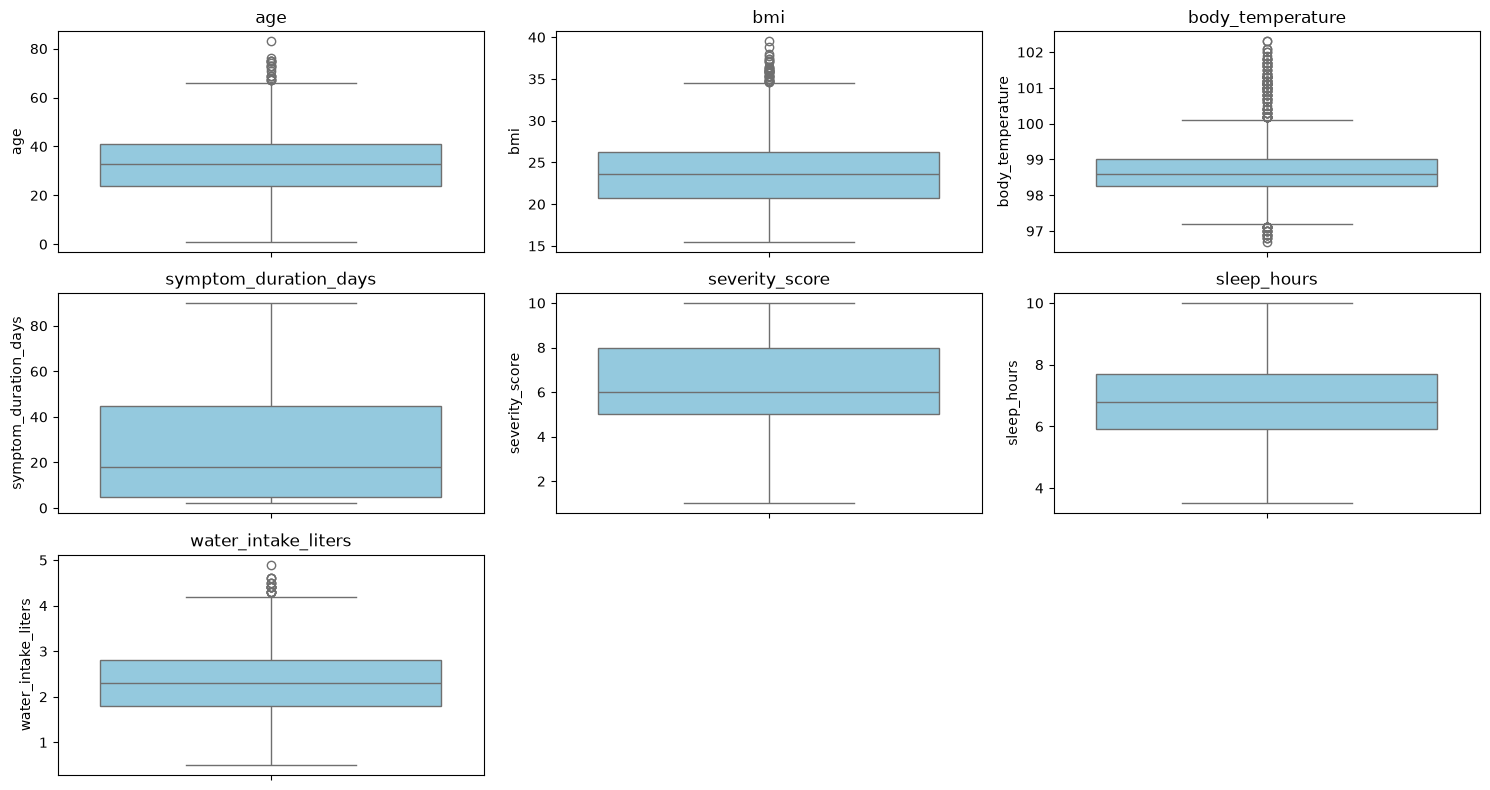

In [18]:
# ======================================
# Boxplots for Numerical Columns
# ======================================

plt.figure(figsize=(15, 8))

for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(y=df[col], color="skyblue")
    plt.title(col)

plt.tight_layout()
plt.show()

The IQR method is used to identify outliers in numerical features. Boxplots visually display the spread of data and highlight observations that fall outside the whiskers, indicating potential outliers.

In [19]:
# ======================================
# Treat Outliers Using IQR Capping
# ======================================

outlier_cols = ["age", "bmi", "body_temperature", "water_intake_liters"]

for col in outlier_cols:

    # Calculate Quartiles
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    # Calculate Lower and Upper Limits
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    # Cap the outliers
    df[col] = df[col].clip(lower=lower_limit, upper=upper_limit)

print("Outliers treated successfully using IQR capping!")

Outliers treated successfully using IQR capping!


The Interquartile Range (IQR) method is used to identify extreme values in numerical columns. Instead of removing patient records, outlier values are capped within the lower and upper IQR limits using the clip() function. This preserves all observations while reducing the effect of extreme values on machine learning models.

In [20]:
# ======================================
# Verify Outliers After Treatment
# ======================================

outlier_summary = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower_limit) | (df[col] > upper_limit)).sum()

    outlier_summary.append({
        "Column": col,
        "Outlier Count": outliers,
        "Outlier Percentage": round((outliers / len(df)) * 100, 2)
    })

pd.DataFrame(outlier_summary)

,Column,Outlier Count,Outlier Percentage
0,age,0,0.0
1,bmi,0,0.0
2,body_temperature,0,0.0
3,symptom_duration_days,0,0.0
4,severity_score,0,0.0
5,sleep_hours,0,0.0
6,water_intake_liters,0,0.0


In [21]:
# ======================================
# Save Preprocessed Dataset
# ======================================

df.to_csv("../data/dermatology_preprocessed_dataset.csv", index=False)

print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!
